In [1]:
# Install Hugging Face datasets, transformers, and evaluation metrics
!pip install -q transformers datasets evaluate rouge_score bert_score accelerate sentencepiece protobuf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re
import torch
import numpy as np
import pandas as pd
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    MBartForConditionalGeneration,
    MBart50TokenizerFast,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq
)
import evaluate

# Set device to GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [4]:
LANGUAGE = "hindi"  # Can be changed to "bengali", "nepali", "telugu", etc.
NUM_EVAL_SAMPLES = 50

print(f"Loading XL-Sum dataset for language: {LANGUAGE} from Parquet branch...")

# Load directly from Hugging Face's auto-converted Parquet branch to bypass xlsum.py
dataset = load_dataset(
    "parquet",
    data_files={
        "train": f"hf://datasets/csebuetnlp/xlsum@refs/convert/parquet/{LANGUAGE}/train/*.parquet",
        "validation": f"hf://datasets/csebuetnlp/xlsum@refs/convert/parquet/{LANGUAGE}/validation/*.parquet",
        "test": f"hf://datasets/csebuetnlp/xlsum@refs/convert/parquet/{LANGUAGE}/test/*.parquet",
    }
)

# Subset the test and train sets for rapid experimentation
train_dataset = dataset["train"].select(range(500))
test_dataset = dataset["test"].select(range(NUM_EVAL_SAMPLES))

print(f"Train samples selected: {len(train_dataset)}")
print(f"Test samples selected: {len(test_dataset)}")

# Inspect a sample
print("\n--- Sample Article ---")
print(test_dataset[0]["text"][:300] + "...")
print("\n--- Reference Summary ---")
print(test_dataset[0]["summary"])

Loading XL-Sum dataset for language: hindi from Parquet branch...


hindi/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

hindi/train/0000.parquet: downloading bytes:           |  0.00B            

hindi/train/0001.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

hindi/train/0001.parquet: downloading bytes:           |  0.00B            

hindi/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 21.4MB            

... (3 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Train samples selected: 500
Test samples selected: 50

--- Sample Article ---
नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को ती...

--- Reference Summary ---
मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.


In [5]:
rouge_metric = evaluate.load("rouge")
bertscore_metric = evaluate.load("bertscore")

def compute_evaluation_metrics(predictions, references):
    """
    Computes ROUGE-1, ROUGE-2, ROUGE-L, and mBERTScore (F1).
     Note: Standard Rouge library uses basic tokenization; setting use_stemmer=False
    and passing a custom whitespace tokenizer ensures compatibility with Indic scripts.
    """
    # 1. Compute ROUGE scores (using whitespace tokenization for multilingual scripts)
    rouge_results = rouge_metric.compute(
        predictions=predictions,
        references=references,
        tokenizer=lambda x: x.split()
    )

    # 2. Compute mBERTScore using 'bert-base-multilingual-cased'
    bert_results = bertscore_metric.compute(
        predictions=predictions,
        references=references,
        model_type="bert-base-multilingual-cased",
        device=device
    )

    return {
        "ROUGE-1": round(rouge_results["rouge1"] * 100, 2),
        "ROUGE-2": round(rouge_results["rouge2"] * 100, 2),
        "ROUGE-L": round(rouge_results["rougeL"] * 100, 2),
        "mBERTScore (Precision)": round(np.mean(bert_results["precision"]) * 100, 2),
        "mBERTScore (Recall)": round(np.mean(bert_results["recall"]) * 100, 2),
        "mBERTScore (F1)": round(np.mean(bert_results["f1"]) * 100, 2)
    }

In [6]:
mt5_model_name = "csebuetnlp/mT5_multilingual_XLSum"
print(f"Loading mT5 model and tokenizer: {mt5_model_name}...")

mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_model_name)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(mt5_model_name).to(device)

# Helper function to normalize whitespace as recommended by XL-Sum authors
WHITESPACE_HANDLER = lambda k: re.sub('\s+', ' ', re.sub('\n+', ' ', k.strip()))

def generate_mt5_summaries(texts, batch_size=8):
    summaries = []
    mt5_model.eval()

    for i in range(0, len(texts), batch_size):
        batch_texts = [WHITESPACE_HANDLER(t) for t in texts[i:i+batch_size]]
        inputs = mt5_tokenizer(
            batch_texts,
            max_length=512,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            output_ids = mt5_model.generate(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                max_length=84,
                no_repeat_ngram_size=2,
                num_beams=4
            )

        batch_summaries = mt5_tokenizer.batch_decode(
            output_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )
        summaries.extend(batch_summaries)

    return summaries

print("Generating summaries with mT5...")
mt5_predictions = generate_mt5_summaries(test_dataset["text"])
print("mT5 inference complete!")

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1361/948217062.py:8: SyntaxWarning: invalid escape sequence '\s'
  WHITESPACE_HANDLER = lambda k: re.sub('\s+', ' ', re.sub('\n+', ' ', k.strip()))


Loading mT5 model and tokenizer: csebuetnlp/mT5_multilingual_XLSum...


config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Generating summaries with mT5...
mT5 inference complete!


In [10]:
import gc
import sys

# 1. Clear stuck traceback frames & previous gradients from GPU VRAM
if hasattr(sys, "last_traceback"):
    sys.last_traceback = None
if "mt5_model" in globals():
    mt5_model.to("cpu")
if "trainer" in globals():
    del trainer
if "mbart_model" in globals():
    mbart_model.zero_grad(set_to_none=True)  # Frees stuck 2.4GB gradients from previous crash!

gc.collect()
torch.cuda.empty_cache()

mbart_model_name = "facebook/mbart-large-50"
LANG_CODE = "hi_IN"  # Use 'bn_IN' for Bengali, 'ne_NP' for Nepali, 'te_IN' for Telugu

if "mbart_model" not in globals():
    print(f"Loading mBART model and tokenizer: {mbart_model_name}...")
    mbart_tokenizer = MBart50TokenizerFast.from_pretrained(mbart_model_name, src_lang=LANG_CODE, tgt_lang=LANG_CODE)
    mbart_model = MBartForConditionalGeneration.from_pretrained(mbart_model_name).to(device)
else:
    print("Using already loaded mBART model and tokenizer from memory...")
    mbart_model.to(device)

# 2. FREEZE Shared Embeddings (250k vocab = 978MB tensor) & Encoder to prevent OOM
# Fine-tuning only the Decoder adapts mBART to summarization using < 5GB VRAM
for param in mbart_model.parameters():
    param.requires_grad = False
for param in mbart_model.model.decoder.layers.parameters():
    param.requires_grad = True

mbart_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
mbart_model.config.use_cache = False

# 3. Preprocess data
def preprocess_mbart(examples):
    inputs = [WHITESPACE_HANDLER(doc) for doc in examples["text"]]
    model_inputs = mbart_tokenizer(inputs, max_length=256, truncation=True, padding="max_length")

    labels = mbart_tokenizer(text_target=examples["summary"], max_length=64, truncation=True, padding="max_length")
    labels["input_ids"] = [
        [(l if l != mbart_tokenizer.pad_token_id else -100) for l in label]
        for label in labels["input_ids"]
    ]
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

small_train_dataset = train_dataset.select(range(200))
tokenized_train = small_train_dataset.map(preprocess_mbart, batched=True, remove_columns=train_dataset.column_names)

# 4. Train using Adafactor on Decoder layers
training_args = Seq2SeqTrainingArguments(
    output_dir="./mbart_xlsum_hindi",
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    optim="adafactor",
    learning_rate=5e-5,
    num_train_epochs=1,
    fp16=torch.cuda.is_available(),
    logging_steps=10,
    save_strategy="no",
    report_to="none"
)

trainer = Seq2SeqTrainer(
    model=mbart_model,
    args=training_args,
    train_dataset=tokenized_train,
    processing_class=mbart_tokenizer,
    data_collator=DataCollatorForSeq2Seq(mbart_tokenizer, model=mbart_model)
)

print(f"Free GPU Memory before training: {torch.cuda.mem_get_info()[0] / 1024**3:.2f} GB")
print("Fine-tuning mBART on XL-Sum subset...")
trainer.train()

# 5. Re-enable cache for inference
mbart_model.config.use_cache = True

def generate_mbart_summaries(texts, batch_size=4):
    summaries = []
    mbart_model.eval()

    for i in range(0, len(texts), batch_size):
        batch_texts = [WHITESPACE_HANDLER(t) for t in texts[i:i+batch_size]]
        inputs = mbart_tokenizer(
            batch_texts,
            max_length=384,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            output_ids = mbart_model.generate(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
                forced_bos_token_id=mbart_tokenizer.lang_code_to_id[LANG_CODE],
                max_length=84,
                no_repeat_ngram_size=2,
                num_beams=4
            )

        batch_summaries = mbart_tokenizer.batch_decode(
            output_ids,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )
        summaries.extend(batch_summaries)

    return summaries

print("Generating summaries with mBART...")
mbart_predictions = generate_mbart_summaries(test_dataset["text"])
print("mBART inference complete!")

# Offload mBART from GPU so Cell 7 (mBERTScore) has full GPU memory
mbart_model.zero_grad(set_to_none=True)
mbart_model.to("cpu")
del trainer
gc.collect()
torch.cuda.empty_cache()

Using already loaded mBART model and tokenizer from memory...


Map:   0%|          | 0/200 [00:00<?, ? examples/s]

Free GPU Memory before training: 9.99 GB
Fine-tuning mBART on XL-Sum subset...


Step,Training Loss
10,17.159592
20,16.371985


Generating summaries with mBART...
mBART inference complete!


In [11]:
references = test_dataset["summary"]

print("Calculating evaluation metrics for mT5...")
mt5_scores = compute_evaluation_metrics(mt5_predictions, references)

print("Calculating evaluation metrics for mBART...")
mbart_scores = compute_evaluation_metrics(mbart_predictions, references)

# Create a DataFrame for side-by-side comparison
comparison_df = pd.DataFrame([mt5_scores, mbart_scores], index=["mT5 (Multilingual T5)", "mBART-50"])
print("\n=== Performance Comparison on XL-Sum (" + LANGUAGE.capitalize() + ") ===")
display(comparison_df)

Calculating evaluation metrics for mT5...


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Calculating evaluation metrics for mBART...

=== Performance Comparison on XL-Sum (Hindi) ===


,ROUGE-1,ROUGE-2,ROUGE-L,mBERTScore (Precision),mBERTScore (Recall),mBERTScore (F1)
mT5 (Multilingual T5),33.98,15.45,28.71,78.37,75.74,76.99
mBART-50,22.85,6.73,18.96,72.05,70.77,71.37


ORIGINAL TEXT (Truncated):
नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है. सरकारी वकील अजय मिश्रा ने यह जानकारी दी है. कुछ दिन पहले एटीएस ने मध्य प्रदेश के इंदौर शहर से साध्वी प्रज्ञा सिंह ठाकुर को गिरफ़्तार किया था. नासिक की अदालत ने प्रज्ञा सिंह और दो अन्य अभियुक्तों को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का भी फ़ैसला दिया. आवेदन एटीएस ने अदालत में इस टेस्ट के लिए ...

ACTUAL REFERENCE SUMMARY:
मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्वी प्रज्ञा सिंह ठाकुर को अब पॉलीग्राफ़, ब्रेन मैपिंग और नॉर्को टेस्ट से गुज़रना होगा. ये सारे टेस्ट झूठ पकड़ने के लिए किए जाते हैं.

mT5 GENERATED SUMMARY:
मालेगाँव धमाके के अभियुक्त साध्वी प्रज्ञा सिंह ठाकुर को तीन नवंबर तक के लिए पुलिस हिरासत में रखने का आदेश दिया गया है.

mBART GENERATED SUMMARY:
नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकवाद निरोधक दस्ते (एटीएस) के अनुरोध पर ये आदेश दिया है.



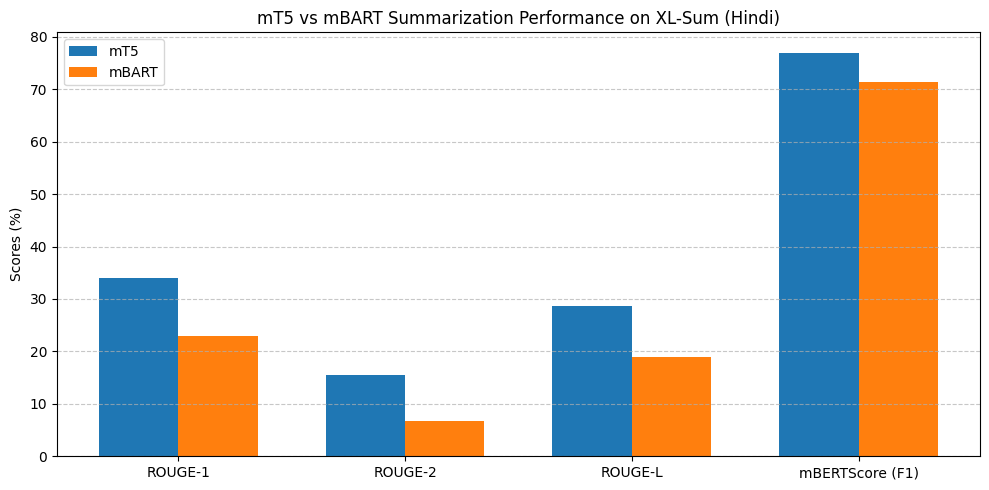

In [12]:
import matplotlib.pyplot as plt

# 1. Print Qualitative Comparison for Sample 0
sample_idx = 0
print("=================================================================")
print(f"ORIGINAL TEXT (Truncated):\n{test_dataset[sample_idx]['text'][:400]}...\n")
print(f"ACTUAL REFERENCE SUMMARY:\n{references[sample_idx]}\n")
print(f"mT5 GENERATED SUMMARY:\n{mt5_predictions[sample_idx]}\n")
print(f"mBART GENERATED SUMMARY:\n{mbart_predictions[sample_idx]}")
print("=================================================================\n")

# 2. Plot Bar Chart of Metrics
metrics_to_plot = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "mBERTScore (F1)"]
x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, [mt5_scores[m] for m in metrics_to_plot], width, label='mT5')
rects2 = ax.bar(x + width/2, [mbart_scores[m] for m in metrics_to_plot], width, label='mBART')

ax.set_ylabel('Scores (%)')
ax.set_title(f'mT5 vs mBART Summarization Performance on XL-Sum ({LANGUAGE.capitalize()})')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()